# What can Instagram engagement tell Alfido Tech?

Compare post formats, tags and discovery signals in a small account network. Use the results to design a posting experiment for an internship audience. The source has no account labelled as Alfido Tech.

[Assigned Kaggle dataset](https://www.kaggle.com/datasets/bhanupratapbiswas/instgram)

## Load the assigned data
Run the notebook from top to bottom. The first run downloads the public Kaggle ZIP. For offline use, place the same archive at `data/instgram.zip` beside the notebook.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import Request, urlopen
from zipfile import ZipFile
from hashlib import sha256

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

TEAL, AMBER = "#187c77", "#bd6b32"
plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlepad": 12})
slug = 'instgram'
archive = Path("data") / (slug + ".zip")
if not archive.is_file():
    archive.parent.mkdir(parents=True, exist_ok=True)
    url = "https://api.kaggle.com/v1/datasets/download/bhanupratapbiswas/" + slug
    with urlopen(Request(url, headers={"User-Agent": "Alfido-coursework/1.0"}), timeout=120) as response:
        payload = response.read()
    with ZipFile(BytesIO(payload)) as downloaded:
        assert downloaded.testzip() is None, "Incomplete dataset archive"
    archive.write_bytes(payload)

# Fingerprints identify the exact source tables used for the saved results.
expected = {'comments.csv': '5a52d8146769b8e18bea879aed69f3acbb4836d4b4e10097727cd0a950168fc5',
 'follows.csv': '55367f7272840634830093a17eb12bb97223a5d01e4cfffcaee81ca21a9601be',
 'likes.csv': '1ec14df7f4da2c43a17fa1d0657e034b07439d6bfa27b3e0e44e0752332e31e9',
 'photo_tags.csv': 'fd05d2b374a333e415e21e0242af3bc82d9a6b7618640891722c55187bfb3dd2',
 'photos.csv': '8e6a4a1e32f9c1c600a15c01f667ba5694d9795d194d320b5915ac00bb878a6a',
 'tags.csv': '34464608b16bfae40626b6a5da1938c41c94d0a1f21f11c10a60816921958ad4',
 'users.csv': 'f02930f9ba8de5d6296a5080ee0418aaee73b56d5cfa5bc14f369c62d78fdc3b'}

def read_table(filename):
    with ZipFile(archive) as source:
        content = source.read(filename)
    if sha256(content).hexdigest() != expected[filename]:
        raise ValueError(f"{filename} differs from the snapshot used for this report.")
    return pd.read_csv(BytesIO(content))

def profile(frame):
    return pd.DataFrame({"data_type": frame.dtypes.astype(str), "missing": frame.isna().sum(),
                         "distinct_values": frame.nunique()})

## Inspect the seven source tables
Photos are the unit of analysis. Users may own many photos, and photos may receive many likes, comments and tags. Count each event type before joining it to photos to avoid multiplying events.

In [2]:
tables = {name: read_table(name + ".csv") for name in
          ["photos", "users", "likes", "comments", "follows", "tags", "photo_tags"]}
for table in tables.values():
    table.columns = table.columns.str.strip().str.lower().str.replace(r"\s+", "_", regex=True)
audit = pd.DataFrame({name: {"rows": len(t), "columns": len(t.columns), "blank_cells": int(t.isna().sum().sum()),
                            "duplicate_rows": int(t.duplicated().sum())} for name, t in tables.items()}).T
display(audit)
display(pd.concat({name: profile(t) for name, t in tables.items()}, names=["table", "column"]))

,rows,columns,blank_cells,duplicate_rows
photos,257,6,0,0
users,100,6,0,0
likes,8782,5,0,0
comments,7488,8,0,0
follows,7623,5,0,0
tags,21,4,0,0
photo_tags,501,3,0,0


data_type  missing  distinct_values
table      column                                                 
photos     id                      int64        0              257
           image_link             object        0              257
           user_id                 int64        0               74
           created_dat            object        0                1
           insta_filter_used      object        0                2
           photo_type             object        0                3
users      id                      int64        0              100
           name                   object        0              100
           created_time           object        0              100
           private/public         object        0                2
           post_count              int64        0               23
           verified_status        object        0                2
likes      user                    int64        0               77
           photo                   int64        0              257
           created_time           object        0                1
           following_or_not       object        0                2
           like_type              object        0                7
comments   id                      int64        0             7488
           comment                object        0             7467
           user_id                 int64        0               77
           photo_id                int64        0              257
           created_timestamp      object        0                1
           posted_date            object        0                1
           emoji_used             object        0                2
           hashtags_used_count     int64        0                7
follows    follower                int64        0               77
           followee                int64        0              100
           created_time           object        0                1
           is_follower_active      int64        0                2
           followee_acc_status    object        0                3
tags       id                      int64        0               21
           tag_text               object        0               21
           created_time           object        0                1
           location               object        0                9
photo_tags photo                   int64        0              190
           tag_id                  int64        0               21
           user_id                 int64        0                4

In [3]:
p = tables["photos"].rename(columns={"id": "post", "user_id": "author", "photo_type": "format",
                                     "created_dat": "posted_at"}).copy()
users, likes, comments = tables["users"], tables["likes"], tables["comments"]
follows, tags, bridge = tables["follows"], tables["tags"], tables["photo_tags"]
assert p.post.is_unique and users.id.is_unique and tags.id.is_unique and comments.id.is_unique
assert not likes.duplicated(["user", "photo"]).any()
assert not follows.duplicated(["follower", "followee"]).any()
assert not bridge.duplicated(["photo", "tag_id"]).any()
for ids in [likes.photo, comments.photo_id, bridge.photo]:
    assert ids.isin(p.post).all()
for ids in [p.author, follows.follower, follows.followee, likes.user, comments.user_id]:
    assert ids.isin(users.id).all()
assert bridge.tag_id.isin(tags.id).all()
p["posted_at"] = pd.to_datetime(p.posted_at, format="%d-%m-%Y %H:%M", errors="raise")
follows["followed_at"] = pd.to_datetime(follows.created_time, format="%d-%m-%Y %H:%M", errors="raise")
p["weekday"] = p.posted_at.dt.day_name()
p["hour"] = p.posted_at.dt.hour
display(p.groupby(["weekday","hour"]).size().rename("posts").to_frame())
print(f"Post timestamps: {p.posted_at.nunique()}. Follow timestamps: {follows.followed_at.nunique()}.")
print(f"First / last post: {p.posted_at.min()} / {p.posted_at.max()} (source timezone unspecified).")

,,posts
weekday,hour,
Thursday,8,257


Post timestamps: 1. Follow timestamps: 1.
First / last post: 2023-04-13 08:04:00 / 2023-04-13 08:04:00 (source timezone unspecified).


## Engagement per 100 followers
Count incoming follow edges per author. Use this snapshot denominator for likes and comments per 100 followers. People outside the follower base can interact and a person can both like and comment, so these rates count events rather than unique people reached.

In [4]:
p["followers"] = p.author.map(follows.groupby("followee").follower.nunique()).fillna(0).astype(int)
p["likes"] = p.post.map(likes.groupby("photo").size()).fillna(0).astype(int)
p["comments"] = p.post.map(comments.groupby("photo_id").size()).fillna(0).astype(int)
p["tag_count"] = p.post.map(bridge.groupby("photo").tag_id.nunique()).fillna(0).astype(int)
denominator = p.followers.replace(0, np.nan)
p["likes_per100"] = 100*p.likes/denominator
p["comments_per100"] = 100*p.comments/denominator
p["events_per100"] = p.likes_per100 + p.comments_per100
assert p.likes.sum() == len(likes) and p.comments.sum() == len(comments)
display(p[["followers", "likes", "comments", "tag_count", "events_per100"]].describe().round(2))
print(f"Zero-follower posts excluded from normalized rates: {denominator.isna().sum()}.")

,followers,likes,comments,tag_count,events_per100
count,257.00,257.00,257.00,257.00,257.00
mean,76.31,34.17,29.14,1.95,82.97
std,0.46,3.61,3.45,1.60,6.36
min,76.00,25.00,21.00,0.00,64.94
25%,76.00,31.00,27.00,0.00,78.95
50%,76.00,34.00,29.00,2.00,82.89
75%,77.00,37.00,31.00,3.00,86.84
max,77.00,48.00,39.00,5.00,103.95


Zero-follower posts excluded from normalized rates: 0.


,posts,authors,median_likes_per100,median_comments_per100,median_events_per100
format,,,,,
carousel,50,42,44.16,37.91,82.89
video,52,43,43.79,38.16,82.89
photo,155,63,45.45,38.16,81.82


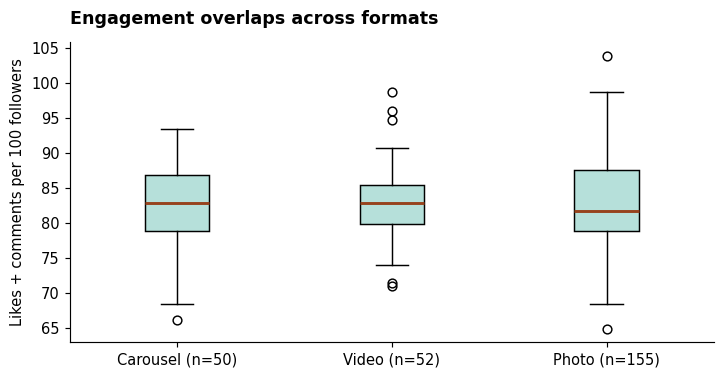

In [5]:
formats = p.groupby("format").agg(posts=("post", "size"), authors=("author", "nunique"),
            median_likes_per100=("likes_per100", "median"), median_comments_per100=("comments_per100","median"),
            median_events_per100=("events_per100", "median")).sort_values("median_events_per100", ascending=False)
display(formats.round(2))
fig, ax = plt.subplots(figsize=(7.0, 3.7))
ax.boxplot([p.loc[p["format"].eq(f), "events_per100"].dropna() for f in formats.index],
           tick_labels=[f"{f.title()} (n={formats.at[f,'posts']})" for f in formats.index],
           patch_artist=True, boxprops={"facecolor":"#b6e0da"}, medianprops={"color":"#97431d","linewidth":2})
ax.set(title="Engagement overlaps across formats", ylabel="Likes + comments per 100 followers")
plt.tight_layout()
plt.show()

## Hashtag reach and engagement
Count distinct posts per tag and compare their median engagement. Multi-tag posts appear in several tag groups. Tag popularity and differences between post formats or authors can affect these descriptive comparisons.

,posts,median_events_per100
tag_text,,
smile,59,83.1
beach,42,81.7
party,39,82.9
fun,38,81.7
food,24,84.9
lol,24,83.1
concert,24,82.9
hair,23,81.6


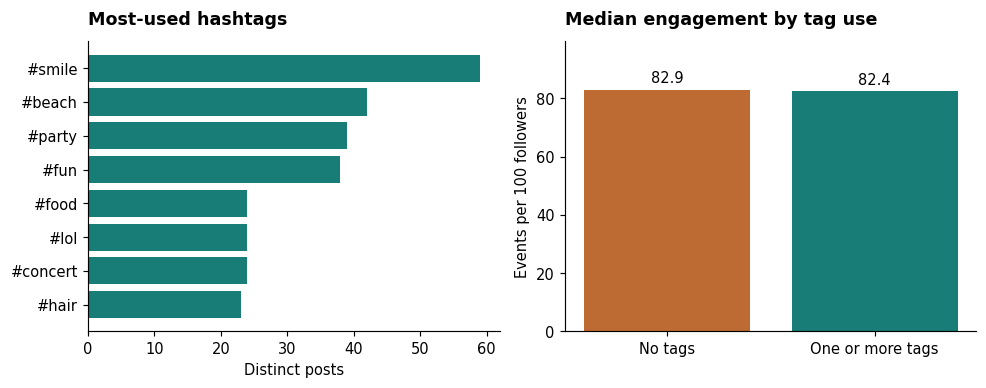

,size,median
tagged,,
No tags,67,82.89
One or more tags,190,82.36


In [6]:
tagged = (bridge.merge(tags[["id","tag_text"]], left_on="tag_id", right_on="id", validate="many_to_one")
          .merge(p[["post","events_per100"]], left_on="photo", right_on="post", validate="many_to_one"))
tag_stats = tagged.groupby("tag_text").agg(posts=("post","nunique"), median_events_per100=("events_per100","median"))
popular = tag_stats.sort_values(["posts","median_events_per100"], ascending=False).head(8).iloc[::-1]
display(popular.iloc[::-1].round(1))
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
axes[0].barh(["#"+t for t in popular.index], popular.posts, color=TEAL)
axes[0].set(title="Most-used hashtags", xlabel="Distinct posts")
tag_groups = p.assign(tagged=np.where(p.tag_count.gt(0), "One or more tags", "No tags")).groupby("tagged")
tag_medians = tag_groups.events_per100.median()
bars = axes[1].bar(tag_medians.index, tag_medians, color=[AMBER, TEAL])
axes[1].bar_label(bars, fmt="%.1f", padding=3)
axes[1].set(title="Median engagement by tag use", ylabel="Events per 100 followers", ylim=(0,tag_medians.max()*1.2))
plt.tight_layout()
plt.show()
display(tag_groups.events_per100.agg(["size","median"]).round(2))

## Discovery and follower growth
Use the event-level following flag to count likes marked as coming from non-followers. This is an exposure signal. The single follow timestamp and absence of follow/unfollow history prevent estimation of conversion or growth over time.

,count,sum,mean
format,,,
carousel,1693,559,0.330
photo,5330,1771,0.332
video,1759,599,0.341


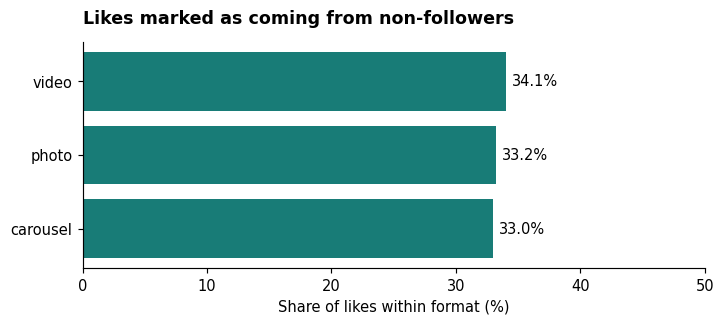

In [7]:
nonfollower = likes["following_or_not"].str.strip().str.lower().eq("no")
outside = int(nonfollower.sum())
reach = likes.assign(outside=nonfollower).merge(p[["post","format"]], left_on="photo", right_on="post",
                                                validate="many_to_one")
discovery = reach.groupby("format").outside.agg(["count","sum","mean"])
display(discovery.round(3))
fig, ax = plt.subplots(figsize=(7,3.2))
bars = ax.barh(discovery.index, 100*discovery["mean"], color=TEAL)
ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.set(title="Likes marked as coming from non-followers", xlabel="Share of likes within format (%)", xlim=(0,50))
plt.tight_layout()
plt.show()

In [8]:
print(f"Posts: {len(p)} across {p.author.nunique()} posting accounts")
print(f"Recorded post times: {p.posted_at.nunique()} | Recorded follow times: {follows.followed_at.nunique()}")
print(f"Likes marked non-follower: {outside:,} of {len(likes):,} ({nonfollower.mean():.1%})")

Posts: 257 across 74 posting accounts
Recorded post times: 1 | Recorded follow times: 1
Likes marked non-follower: 2,929 of 8,782 (33.4%)


In [9]:
edges = follows[["follower", "followee"]].rename(columns={"follower":"user", "followee":"author"})
linked = (likes.merge(p[["post", "author"]], left_on="photo", right_on="post", validate="many_to_one")
          .merge(edges, on=["user","author"], how="left", indicator=True, validate="many_to_one"))
display(pd.crosstab(linked.following_or_not, linked["_merge"].eq("both"),
                    rownames=["Like marked as following"], colnames=["Edge exists in snapshot"]))

Edge exists in snapshot,False,True
Like marked as following,,
no,17,2912
yes,35,5818


Of 2,929 likes marked as coming from non-followers, 2,912 have a matching follow edge in the snapshot. The order of these events is unavailable. Use platform Insights to measure discovery in the pilot. The file cannot establish how many people became followers after liking a post.

## Four-week content calendar

Use India Standard Time for this proposed Alfido Tech pilot. All source posts were recorded at 08:04 on 13 April 2023, so the chosen hours are experimental. The near-tie in format medians supports testing all three formats.

| Day and topic | Weeks 1 and 3 | Weeks 2 and 4 |
|---|---|---|
| Tuesday: one data-cleaning tip, carousel | 12:30 IST | 18:30 IST |
| Thursday: one-minute Python demonstration, video | 18:30 IST | 12:30 IST |
| Saturday: student project and a question, photo | 12:30 IST | 18:30 IST |

### Five ways to improve engagement

1. Show one worked example in each carousel and put the final code on the last slide. Compare saves per 100 followers across the four carousels.
2. End each video with a specific debugging question, and answer comments within a day. Compare comments per 100 followers after 48 hours.
3. Alternate the two time slots within each weekday and format. Record followers at publication. Compare the 48-hour interaction rates within matched weekday/format pairs.
4. Test a small set of relevant tags, such as #DataScience and #Python. Hold the tag set fixed during the timing pilot, then run a separate tagged versus untagged trial. The sample median was 82.36 events per 100 on tagged posts and 82.89 on untagged posts.
5. Give each project spotlight a reason to follow, such as the next exercise in a series. Use native Insights to log non-follower reach, follows attributed to the post where available, and week-end follower totals. Review net growth separately from likes.

After four weeks each weekday/format has two posts per time slot. Use the better-performing slot for a larger follow-up if the direction is consistent. The small pilot provides a starting estimate.